Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.

Explanation: Loads diabetes.csv into a pandas dataframe and renames the columns to lowercase names with underscores so they are easier to type later. The imports for the whole notebook (preprocessing, the four ensemble methods, and the evaluation metrics) are also placed in this cell, and I print the shape of the dataframe to confirm it has 768 patients and 9 columns (8 features and the outcome).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

df = pd.read_csv("diabetes.csv")
df.columns = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin",
              "bmi", "diabetes_pedigree_function", "age", "outcome"]
print(f"Dataset shape: {df.shape}")

Dataset shape: (768, 9)


Task 2: Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

Explanation: Uses head(), info(), and describe() to view the dataframe. info() shows no null values in any column, but describe() shows a minimum of 0 for glucose, blood_pressure, skin_thickness, insulin and bmi, which is not possible for a living patient, so these zeros are placeholders for missing measurements. pregnancies can validly be 0 and outcome is a 0/1 label, so those are left alone. The last cell counts the zeros in each column to confirm this.

In [3]:
df.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.describe()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   pregnancies                 768 non-null    int64  
 1   glucose                     768 non-null    int64  
 2   blood_pressure              768 non-null    int64  
 3   skin_thickness              768 non-null    int64  
 4   insulin                     768 non-null    int64  
 5   bmi                         768 non-null    float64
 6   diabetes_pedigree_function  768 non-null    float64
 7   age                         768 non-null    int64  
 8   outcome                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
(df == 0).sum()

,0
pregnancies,111
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
diabetes_pedigree_function,0
age,0
outcome,500


Task 3: Quantify and handle implicit missing values using SimpleImputer.

Explanation: Converts the 0s in glucose, blood_pressure, skin_thickness, insulin and bmi to null, then prints the count and percentage of missing values in each column. Since all five of these columns are numeric and several are skewed (especially insulin), I fill them with the median using SimpleImputer(strategy="median") and place the result in a separate imputed df. The last line checks that no missing values remain.

In [7]:
zero_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
for col in zero_cols:
    df.loc[df[col] == 0, col] = np.nan

missing = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_percent": (df.isna().mean() * 100).round(2)})
print(missing)

median_imputer = SimpleImputer(strategy="median")
df_imputed = df.copy()
df_imputed[zero_cols] = median_imputer.fit_transform(df[zero_cols])

print(f"\nMissing values after imputation: {df_imputed.isna().sum().sum()}")

                            missing_count  missing_percent
pregnancies                             0             0.00
glucose                                 5             0.65
blood_pressure                         35             4.56
skin_thickness                        227            29.56
insulin                               374            48.70
bmi                                    11             1.43
diabetes_pedigree_function              0             0.00
age                                     0             0.00
outcome                                 0             0.00

Missing values after imputation: 0


Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

Explanation: Separates the inputs (X) from the target (y = outcome) and splits the data 80/20 with stratify=y so both sets keep the same share of diabetic patients. All eight features are numeric, so the ColumnTransformer applies StandardScaler to all of them. I wrap it in a pipeline so that the scaling is fitted on the training set and then applied to the test set, and I fit the preprocessor on the training set. Scaling matters here because Logistic Regression and the SVC are sensitive to the size of the numbers (insulin goes up to 846 while the pedigree function is under 3).

In [8]:
X = df_imputed.drop(columns=["outcome"])
y = df_imputed["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}\n")

numeric_features = list(X.columns)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
])

preprocess_pipe = Pipeline([("preprocessor", preprocessor)])

X_train_transformed = preprocess_pipe.fit_transform(X_train)
X_test_transformed = preprocess_pipe.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

Training set shape: (614, 8)
Testing set shape: (154, 8)
Class distribution in y_train:
outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64



Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use appropriate plots to show the results.

Explanation: Builds a function, evaluate_model, that prints a confusion matrix, a classification report and the test accuracy, so the identical metrics are used in tasks 6, 7 and 8. The three base models are Logistic Regression, an SVC (with probability=True so it can give probabilities for soft voting) and a Decision Tree with max_depth=5. Hard voting takes the majority class of the three models, while soft voting averages their predicted probabilities. Both are placed in a pipeline with the preprocessor from task 4 and trained on the training set. I also train each base model alone so the ensembles can be compared to them, then plot the test accuracy of all five models in a bar chart and the confusion matrices of the two voting classifiers.

===== Hard Voting =====
Confusion matrix (rows = true, columns = predicted):
                   Pred: No diabetes  Pred: Diabetes
True: No diabetes                 82              18
True: Diabetes                    24              30

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.77      0.82      0.80       100
    Diabetes       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154

Test accuracy: 0.7273

===== Soft Voting =====
Confusion matrix (rows = true, columns = predicted):
                   Pred: No diabetes  Pred: Diabetes
True: No diabetes                 85              15
True: Diabetes                    27              27

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.76      0.85      0.80       100
    Diabetes       0.

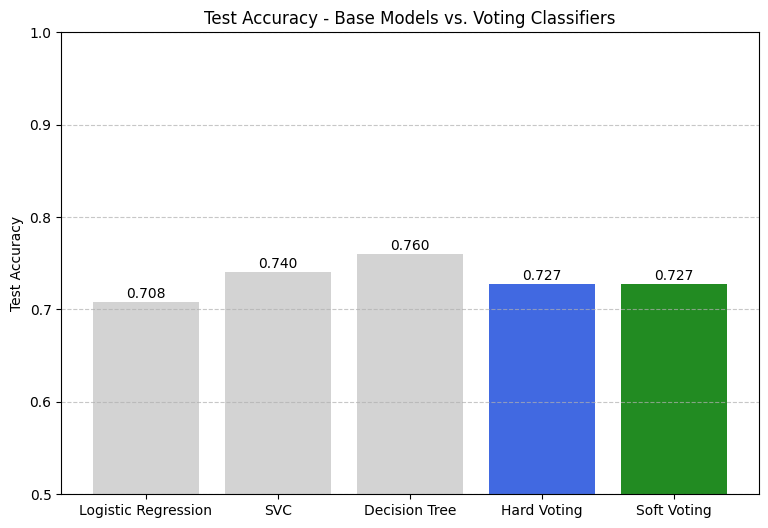

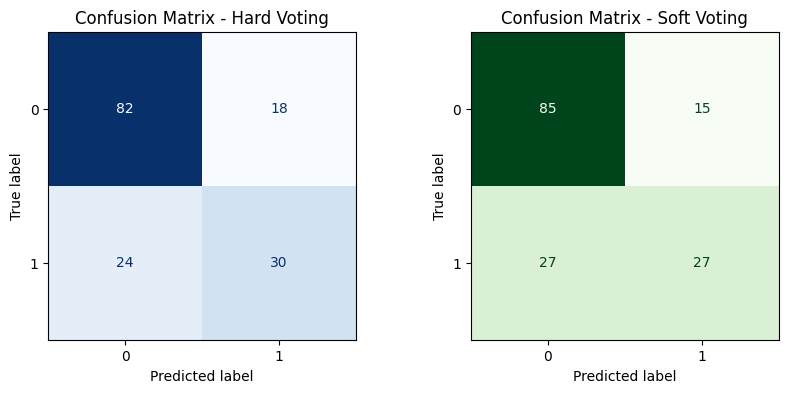

In [9]:
def evaluate_model(name, model):
    y_pred = model.predict(X_test)

    print(f"===== {name} =====")
    print("Confusion matrix (rows = true, columns = predicted):")
    print(pd.DataFrame(confusion_matrix(y_test, y_pred),
                       index=["True: No diabetes", "True: Diabetes"],
                       columns=["Pred: No diabetes", "Pred: Diabetes"]))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))
    acc = accuracy_score(y_test, y_pred)
    print(f"Test accuracy: {acc:.4f}\n")
    return acc

estimators = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("svc", SVC(probability=True, random_state=42)),
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
]

hard_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("voting", VotingClassifier(estimators=estimators, voting="hard")),
])
soft_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("voting", VotingClassifier(estimators=estimators, voting="soft")),
])
hard_clf.fit(X_train, y_train)
soft_clf.fit(X_train, y_train)

hard_acc = evaluate_model("Hard Voting", hard_clf)
soft_acc = evaluate_model("Soft Voting", soft_clf)

base_acc = []
for name, est in estimators:
    base_pipe = Pipeline([("preprocessor", preprocessor), ("model", est)])
    base_pipe.fit(X_train, y_train)
    base_acc.append(base_pipe.score(X_test, y_test))

names = ["Logistic Regression", "SVC", "Decision Tree", "Hard Voting", "Soft Voting"]
accs = base_acc + [hard_acc, soft_acc]
colors = ["lightgray", "lightgray", "lightgray", "royalblue", "forestgreen"]

plt.figure(figsize=(9, 6))
bars = plt.bar(names, accs, color=colors)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.005, f"{acc:.3f}", ha="center")
plt.ylim(0.5, 1.0)
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy - Base Models vs. Voting Classifiers")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(hard_clf, X_test, y_test, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix - Hard Voting")
ConfusionMatrixDisplay.from_estimator(soft_clf, X_test, y_test, ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("Confusion Matrix - Soft Voting")
plt.show()

Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.

Explanation: Builds a pipeline with the same preprocessor followed by a BaggingClassifier of 200 decision trees with bootstrap=True and oob_score=True. Each tree is trained on a random sample of the training set drawn with replacement, so about a third of the training patients are left out of each tree, and the OOB score is the accuracy on those left out patients using only the trees that never saw them. I evaluate it on the test set with the function from task 5, then plot the OOB score and the test accuracy side by side in one bar graph.

===== Bagging (200 Decision Trees) =====
Confusion matrix (rows = true, columns = predicted):
                   Pred: No diabetes  Pred: Diabetes
True: No diabetes                 85              15
True: Diabetes                    25              29

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.77      0.85      0.81       100
    Diabetes       0.66      0.54      0.59        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154

Test accuracy: 0.7403

OOB score: 0.7590


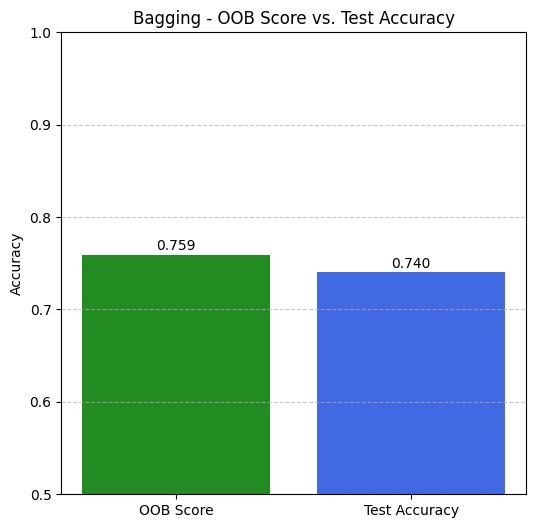

In [10]:
bag_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("bagging", BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=200,
                                  bootstrap=True, oob_score=True, n_jobs=-1, random_state=42)),
])
bag_clf.fit(X_train, y_train)

bag_acc = evaluate_model("Bagging (200 Decision Trees)", bag_clf)
bag_oob = bag_clf.named_steps["bagging"].oob_score_
print(f"OOB score: {bag_oob:.4f}")

plt.figure(figsize=(6, 6))
bars = plt.bar(["OOB Score", "Test Accuracy"], [bag_oob, bag_acc], color=["forestgreen", "royalblue"])
for bar, val in zip(bars, [bag_oob, bag_acc]):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 0.005, f"{val:.3f}", ha="center")
plt.ylim(0.5, 1.0)
plt.ylabel("Accuracy")
plt.title("Bagging - OOB Score vs. Test Accuracy")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

Explanation: Builds a pipeline with the same preprocessor followed by a RandomForestClassifier of 300 trees with max_features="sqrt", so each split only looks at a random subset of about 3 of the 8 features. This is the difference from the bagging model in task 6, which lets every split look at all of the features. I evaluate it with the function from task 5, then take feature_importances_ (the mean decrease in impurity) from the trained forest, using the feature names from task 4, and draw them in a horizontal bar plot sorted from smallest to largest.

===== Random Forest (max_features='sqrt') =====
Confusion matrix (rows = true, columns = predicted):
                   Pred: No diabetes  Pred: Diabetes
True: No diabetes                 84              16
True: Diabetes                    25              29

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154

Test accuracy: 0.7338

OOB score: 0.7704


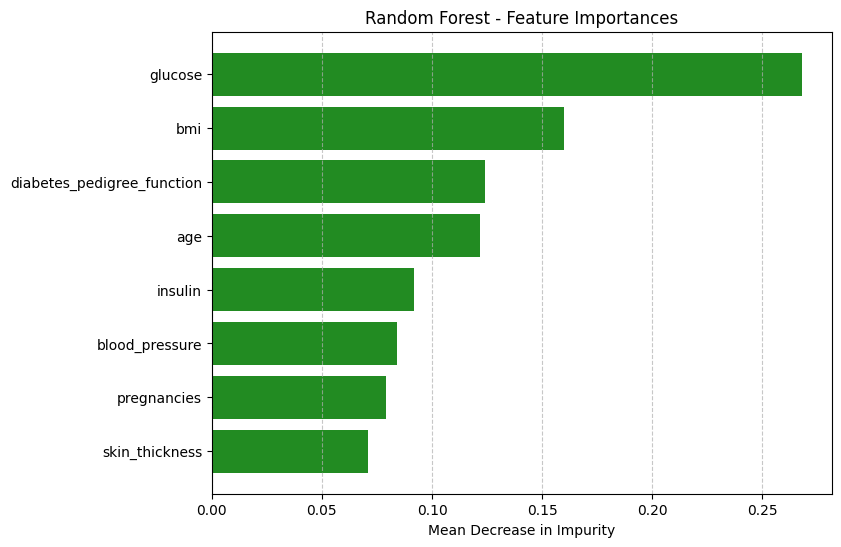

glucose                       0.2682
bmi                           0.1600
diabetes_pedigree_function    0.1242
age                           0.1217
insulin                       0.0916
blood_pressure                0.0842
pregnancies                   0.0790
skin_thickness                0.0710
dtype: float64


In [11]:
rf_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                                  n_jobs=-1, random_state=42)),
])
rf_clf.fit(X_train, y_train)

rf_acc = evaluate_model("Random Forest (max_features='sqrt')", rf_clf)
print(f"OOB score: {rf_clf.named_steps['rf'].oob_score_:.4f}")

importances = pd.Series(rf_clf.named_steps["rf"].feature_importances_, index=feature_names).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importances.index, importances.values, color="forestgreen")
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest - Feature Importances")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

print(importances.sort_values(ascending=False).round(4))

Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

Explanation: Builds a pipeline with the same preprocessor followed by an AdaBoostClassifier that uses decision stumps (DecisionTreeClassifier with max_depth=1) as its base estimator, 200 of them in total. The stumps are trained one after another and after each one the weights of the misclassified patients are increased so the next stump focuses on them. I evaluate it with the function from task 5 and print the training accuracy next to the test accuracy. Then I use staged_score on the transformed data from task 4 to get the training and test accuracy after each stump, and plot both curves on one graph to see whether the training accuracy keeps climbing while the test accuracy stops improving.

===== AdaBoost (200 decision stumps) =====
Confusion matrix (rows = true, columns = predicted):
                   Pred: No diabetes  Pred: Diabetes
True: No diabetes                 85              15
True: Diabetes                    22              32

Classification report:
              precision    recall  f1-score   support

 No diabetes       0.79      0.85      0.82       100
    Diabetes       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154

Test accuracy: 0.7597

Training accuracy: 0.8225
Test accuracy:     0.7597


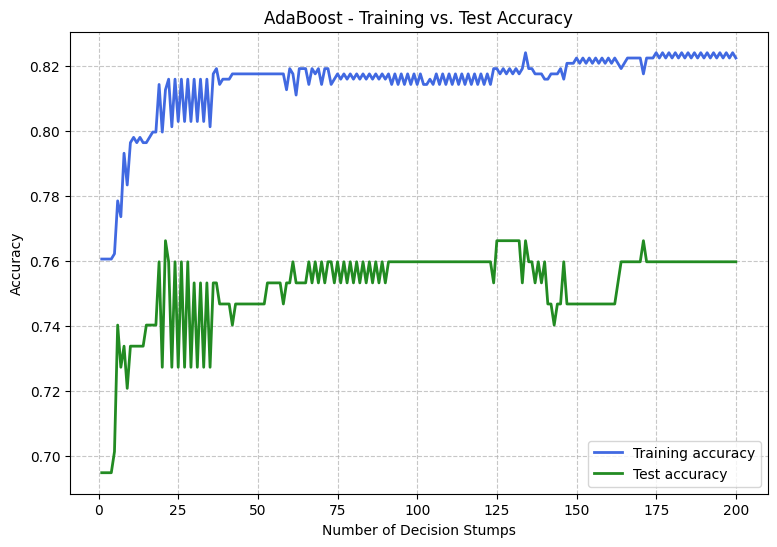

Best test accuracy: 0.7662 at 21 stumps


In [12]:
ada_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("ada", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=42),
                               n_estimators=200, learning_rate=1.0, random_state=42)),
])
ada_clf.fit(X_train, y_train)

ada_acc = evaluate_model("AdaBoost (200 decision stumps)", ada_clf)
print(f"Training accuracy: {ada_clf.score(X_train, y_train):.4f}")
print(f"Test accuracy:     {ada_acc:.4f}")

ada_model = ada_clf.named_steps["ada"]
train_curve = list(ada_model.staged_score(X_train_transformed, y_train))
test_curve = list(ada_model.staged_score(X_test_transformed, y_test))

plt.figure(figsize=(9, 6))
plt.plot(range(1, 201), train_curve, color="royalblue", linewidth=2, label="Training accuracy")
plt.plot(range(1, 201), test_curve, color="forestgreen", linewidth=2, label="Test accuracy")
plt.xlabel("Number of Decision Stumps")
plt.ylabel("Accuracy")
plt.title("AdaBoost - Training vs. Test Accuracy")
plt.legend(loc="lower right")
plt.grid(linestyle="--", alpha=0.7)
plt.show()

print(f"Best test accuracy: {max(test_curve):.4f} at {int(np.argmax(test_curve)) + 1} stumps")

Summary

Explanation: Collects the test accuracy of every model from tasks 5 to 8 into one table so they can be compared directly.

In [13]:
summary = pd.DataFrame({"Test accuracy": [hard_acc, soft_acc, bag_acc, rf_acc, ada_acc]},
                       index=["Hard Voting", "Soft Voting", "Bagging", "Random Forest", "AdaBoost"]).round(3)
print(summary)

               Test accuracy
Hard Voting            0.727
Soft Voting            0.727
Bagging                0.740
Random Forest          0.734
AdaBoost               0.760
